<a href="https://colab.research.google.com/github/viviantothewu-web/trashnet-waste-classification/blob/main/Vivian_Real_World_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

- Mount Drive
- Locate P2 real-world photos (in google drive "Data" folder)
- Load the four trained Seed 0 models
- Apply evaluation preprocessing
- Run predictions
- Calculate accuracy / precision / recall / F1
- Confusion matrices
- Save results CSV
- Compare real-world vs TrashNet performance

In [ ]:
from google.colab import drive
from pathlib import Path

# Mount Google Drive
drive.mount("/content/drive")

# Real-world test dataset location
REAL_WORLD_DIR = Path(
    "/content/drive/MyDrive/Waste_Classification_Project/Data/real_world_test"
)

print("Real-world folder exists:", REAL_WORLD_DIR.exists())
print("Folder:", REAL_WORLD_DIR)

if REAL_WORLD_DIR.exists():
    print("\nClass folders:")
    for folder in sorted(REAL_WORLD_DIR.iterdir()):
        if folder.is_dir():
            print("-", folder.name)

Mounted at /content/drive
Real-world folder exists: True
Folder: /content/drive/MyDrive/Waste_Classification_Project/Data/real_world_test

Class folders:
- cardboard
- glass
- metal
- paper
- plastic
- trash


In [ ]:
#count my portion of photos only
# I labeled mine "P2"

# Count Vivian's P2 real-world photos in each class

CLASS_NAMES = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

total_p2 = 0

for class_name in CLASS_NAMES:
    class_folder = REAL_WORLD_DIR / class_name

    p2_images = sorted(class_folder.glob("*_P2_*.jpg"))

    print(f"{class_name}: {len(p2_images)} P2 images")
    total_p2 += len(p2_images)

print("\nTotal P2 images:", total_p2)

cardboard: 17 P2 images
glass: 17 P2 images
metal: 17 P2 images
paper: 17 P2 images
plastic: 17 P2 images
trash: 17 P2 images

Total P2 images: 102


In [ ]:
#turn into pd first
import pandas as pd

rows = []

for class_name in CLASS_NAMES:
    class_folder = REAL_WORLD_DIR / class_name

    for image_path in sorted(class_folder.glob("*_P2_*.jpg")):
        rows.append({
            "filepath": str(image_path),
            "filename": image_path.name,
            "true_class": class_name
        })

p2_df = pd.DataFrame(rows)

print("Total images:", len(p2_df))
display(p2_df.head(10))

Total images: 102


,filepath,filename,true_class
0,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_001.jpg,cardboard
1,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_002.jpg,cardboard
2,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_003.jpg,cardboard
3,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_004.jpg,cardboard
4,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_005.jpg,cardboard
5,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_006.jpg,cardboard
6,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_007.jpg,cardboard
7,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_008.jpg,cardboard
8,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_009.jpg,cardboard
9,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_010.jpg,cardboard


In [ ]:
#load the .pth
import os
from pathlib import Path

os.chdir("/content")

repo_dir = Path("trashnet-waste-classification")

if repo_dir.exists():
    os.chdir(repo_dir)
    !git pull
else:
    !git clone https://github.com/viviantothewu-web/trashnet-waste-classification.git
    os.chdir(repo_dir)

print("Current folder:", os.getcwd())

Cloning into 'trashnet-waste-classification'...
remote: Enumerating objects: 154, done.
remote: Counting objects: 100% (154/154), done.
remote: Compressing objects: 100% (151/151), done.
remote: Total 154 (delta 78), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (154/154), 18.98 MiB | 13.68 MiB/s, done.
Resolving deltas: 100% (78/78), done.
Current folder: /content/trashnet-waste-classification


In [ ]:
#model = gpu
import torch

from src.transfer_learning import create_pretrained_model
from src.custom_cnn_training import CustomCNN

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Model definitions imported successfully.")

Using device: cuda
GPU: Tesla T4
Model definitions imported successfully.


In [ ]:
#seed 0 checkpoints
from pathlib import Path

project_drive = Path(
    "/content/drive/MyDrive/Waste_Classification_Project"
)

print("Seed 0 model files found:\n")

for file in sorted(project_drive.rglob("*.pth")):
    if "seed0" in file.name.lower():
        print(file)

Seed 0 model files found:

/content/drive/MyDrive/Waste_Classification_Project/Seed_0/customcnn_seed0.pth
/content/drive/MyDrive/Waste_Classification_Project/Seed_0/mobilenetv2_seed0_stage1.pth
/content/drive/MyDrive/Waste_Classification_Project/Seed_0/mobilenetv2_seed0_stage2.pth
/content/drive/MyDrive/Waste_Classification_Project/Seed_0/resnet50_seed0_stage1.pth
/content/drive/MyDrive/Waste_Classification_Project/Seed_0/resnet50_seed0_stage2.pth
/content/drive/MyDrive/Waste_Classification_Project/Seed_0/vgg16_seed0_stage1.pth
/content/drive/MyDrive/Waste_Classification_Project/Seed_0/vgg16_seed0_stage2.pth


In [ ]:
#use the stage 2 checkpoints
SEED0_DIR = Path(
    "/content/drive/MyDrive/Waste_Classification_Project/Seed_0"
)

checkpoint_paths = {
    "Custom CNN": SEED0_DIR / "customcnn_seed0.pth",
    "VGG16": SEED0_DIR / "vgg16_seed0_stage2.pth",
    "ResNet50": SEED0_DIR / "resnet50_seed0_stage2.pth",
    "MobileNetV2": SEED0_DIR / "mobilenetv2_seed0_stage2.pth"
}

for model_name, path in checkpoint_paths.items():
    print(f"{model_name}: {path.exists()}")

Custom CNN: True
VGG16: True
ResNet50: True
MobileNetV2: True


In [ ]:
#same preprossessing as trashnet
from torchvision import transforms

real_world_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print(real_world_transform)

Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [ ]:
#create dataset for P2
from PIL import Image
from torch.utils.data import Dataset

class_to_idx = {
    "cardboard": 0,
    "glass": 1,
    "metal": 2,
    "paper": 3,
    "plastic": 4,
    "trash": 5
}

class RealWorldP2Dataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(row["filepath"]).convert("RGB")
        label = class_to_idx[row["true_class"]]

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
#p2 dataloader
from torch.utils.data import DataLoader

p2_dataset = RealWorldP2Dataset(
    dataframe=p2_df,
    transform=real_world_transform
)

p2_loader = DataLoader(
    p2_dataset,
    batch_size=32,
    shuffle=False
)

print("P2 images:", len(p2_dataset))
print("P2 batches:", len(p2_loader))

P2 images: 102
P2 batches: 4


In [ ]:
#check
images, labels = next(iter(p2_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("First few labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image dtype: torch.float32
First few labels: tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])


In [ ]:
# Load my four trained Seed 0 models

models = {}

# Custom CNN
custom_model = CustomCNN(num_classes=6).to(device)
custom_model.load_state_dict(
    torch.load(
        checkpoint_paths["Custom CNN"],
        map_location=device,
        weights_only=True
    )
)
custom_model.eval()
models["Custom CNN"] = custom_model


# VGG16
vgg_model = create_pretrained_model("vgg16").to(device)
vgg_model.load_state_dict(
    torch.load(
        checkpoint_paths["VGG16"],
        map_location=device,
        weights_only=True
    )
)
vgg_model.eval()
models["VGG16"] = vgg_model


# ResNet50
resnet_model = create_pretrained_model("resnet50").to(device)
resnet_model.load_state_dict(
    torch.load(
        checkpoint_paths["ResNet50"],
        map_location=device,
        weights_only=True
    )
)
resnet_model.eval()
models["ResNet50"] = resnet_model


# MobileNetV2
mobilenet_model = create_pretrained_model("mobilenetv2").to(device)
mobilenet_model.load_state_dict(
    torch.load(
        checkpoint_paths["MobileNetV2"],
        map_location=device,
        weights_only=True
    )
)
mobilenet_model.eval()
models["MobileNetV2"] = mobilenet_model


print("Loaded models:")
for name in models:
    print("-", name)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:06<00:00, 85.7MB/s]


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 180MB/s]


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 148MB/s]


Loaded models:
- Custom CNN
- VGG16
- ResNet50
- MobileNetV2


In [ ]:
#run all 4 models
# Run predictions on Vivian's P2 real-world photos

idx_to_class = {
    0: "cardboard",
    1: "glass",
    2: "metal",
    3: "paper",
    4: "plastic",
    5: "trash"
}

results_df = p2_df.copy()

for model_name, model in models.items():
    predictions = []

    with torch.no_grad():
        for images, labels in p2_loader:
            images = images.to(device)

            outputs = model(images)
            predicted_indices = outputs.argmax(dim=1)

            predictions.extend(predicted_indices.cpu().tolist())

    results_df[model_name] = [
        idx_to_class[pred] for pred in predictions
    ]

print("Predictions complete.")
display(results_df.head(10))

Predictions complete.


,filepath,filename,true_class,Custom CNN,VGG16,ResNet50,MobileNetV2
0,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_001.jpg,cardboard,paper,plastic,paper,paper
1,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_002.jpg,cardboard,paper,paper,cardboard,paper
2,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_003.jpg,cardboard,paper,paper,paper,paper
3,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_004.jpg,cardboard,cardboard,paper,paper,paper
4,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_005.jpg,cardboard,paper,metal,paper,cardboard
5,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_006.jpg,cardboard,paper,metal,metal,cardboard
6,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_007.jpg,cardboard,plastic,metal,paper,cardboard
7,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_008.jpg,cardboard,plastic,cardboard,cardboard,cardboard
8,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_009.jpg,cardboard,paper,paper,paper,cardboard
9,/content/drive/MyDrive/Waste_Classification_Pr...,cardboard_P2_010.jpg,cardboard,plastic,cardboard,cardboard,cardboard


In [ ]:
# Calculate overall accuracy for each model on P2 real-world photos

model_columns = [
    "Custom CNN",
    "VGG16",
    "ResNet50",
    "MobileNetV2"
]

print("P2 Real-World Accuracy")
print("----------------------")

for model_name in model_columns:
    accuracy = (results_df[model_name] == results_df["true_class"]).mean()

    print(f"{model_name}: {accuracy * 100:.2f}%")

P2 Real-World Accuracy
----------------------
Custom CNN: 16.67%
VGG16: 33.33%
ResNet50: 29.41%
MobileNetV2: 28.43%


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

metric_rows = []

for model_name in model_columns:
    y_true = results_df["true_class"]
    y_pred = results_df[model_name]

    metric_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        )
    })

metrics_df = pd.DataFrame(metric_rows)

display(
    metrics_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1": "{:.2%}"
    })
)

,Model,Accuracy,Precision,Recall,F1
0,Custom CNN,16.67%,14.26%,16.67%,14.12%
1,VGG16,33.33%,41.80%,33.33%,32.92%
2,ResNet50,29.41%,33.18%,29.41%,27.82%
3,MobileNetV2,28.43%,39.73%,28.43%,26.58%


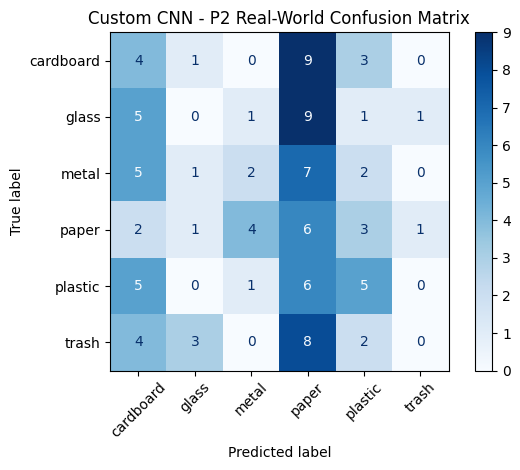

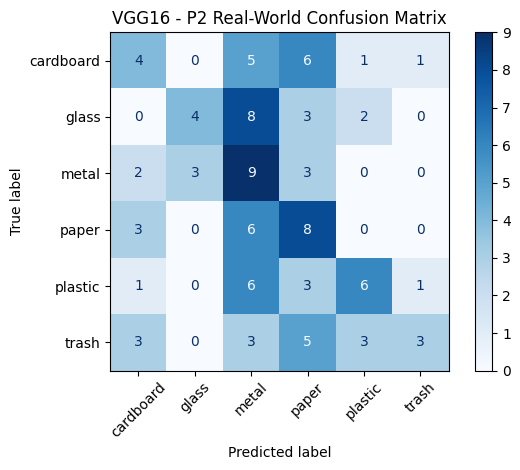

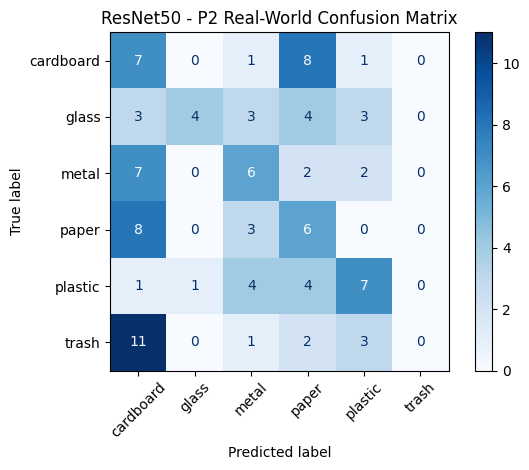

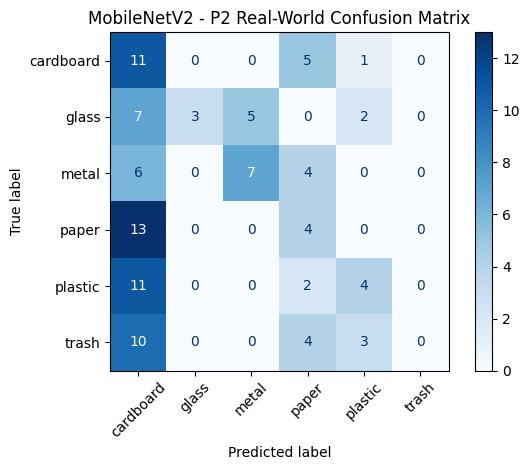

In [ ]:
#confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for model_name in model_columns:
    y_true = results_df["true_class"]
    y_pred = results_df[model_name]

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=CLASS_NAMES
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES
    )

    disp.plot(
        cmap="Blues",
        xticks_rotation=45
    )

    plt.title(f"{model_name} - P2 Real-World Confusion Matrix")
    plt.tight_layout()
    plt.show()

In [ ]:
#per class
from sklearn.metrics import classification_report

for model_name in model_columns:
    print(f"\n{model_name} - P2 Per-Class Report")
    print("=" * 50)

    report = classification_report(
        results_df["true_class"],
        results_df[model_name],
        labels=CLASS_NAMES,
        target_names=CLASS_NAMES,
        zero_division=0
    )

    print(report)


Custom CNN - P2 Per-Class Report
              precision    recall  f1-score   support

   cardboard       0.16      0.24      0.19        17
       glass       0.00      0.00      0.00        17
       metal       0.25      0.12      0.16        17
       paper       0.13      0.35      0.19        17
     plastic       0.31      0.29      0.30        17
       trash       0.00      0.00      0.00        17

    accuracy                           0.17       102
   macro avg       0.14      0.17      0.14       102
weighted avg       0.14      0.17      0.14       102


VGG16 - P2 Per-Class Report
              precision    recall  f1-score   support

   cardboard       0.31      0.24      0.27        17
       glass       0.57      0.24      0.33        17
       metal       0.24      0.53      0.33        17
       paper       0.29      0.47      0.36        17
     plastic       0.50      0.35      0.41        17
       trash       0.60      0.18      0.27        17

    accuracy  

In [ ]:
#save
from pathlib import Path

P2_RESULTS_DIR = Path(
    "/content/drive/MyDrive/Waste_Classification_Project/results/P2"
)

P2_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save prediction for every photo
predictions_path = P2_RESULTS_DIR / "P2_seed0_real_world_predictions.csv"
results_df.to_csv(predictions_path, index=False)

# Save overall metrics
metrics_path = P2_RESULTS_DIR / "P2_seed0_real_world_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

print("Saved:")
print(predictions_path)
print(metrics_path)

Saved:
/content/drive/MyDrive/Waste_Classification_Project/results/P2/P2_seed0_real_world_predictions.csv
/content/drive/MyDrive/Waste_Classification_Project/results/P2/P2_seed0_real_world_metrics.csv
